# 05 - Data-efficiency study

**Owner:** Nitin (Part D)

**Question:** how does the test score change when we have fewer labelled training images, and how much does transfer learning help when labels are scarce?

**What it does.** It trains two models with the shared `train()` function from `src/train.py` on 5%, 10%, 25%, 50% and 100% of the 18,900 training images:

- `scratch_cnn`: our own CNN (Part B), trained from random weights
- `mobilenet_v2_full`: MobileNetV2 pretrained on ImageNet and fully fine-tuned (Part C). It is the best transfer model **on the validation set** (98.22% against 97.69% for ResNet-18 with full fine-tuning), so it is the one we compare.

**Rules.** The validation and test images never shrink: only the training images do (a stratified subset, so every class keeps its share). Everything else is the team setting from `docs/plan.md`: batch 64, Adam, up to 20 epochs, best epoch chosen on validation, test set scored once per run. Each setting is repeated with seeds 0, 1 and 2, and we report the mean and the sample standard deviation (`ddof=1`).

**Results file.** Every run adds one row to `results/metrics.csv`. A run that is already in the file is skipped, so this notebook can be stopped and started again. The 100% rows already exist: `scratch_cnn` from Part B and `mobilenet_v2_full` from Part C.

In [1]:
from pathlib import Path
import contextlib
import io
import os
import sys
import time

# Make imports work whether Jupyter starts in the repo folder or in notebooks/.
project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
os.chdir(project_root)
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.train import MAX_EPOCHS, train
from src.utils import FIGURES_DIR, METRICS_CSV, get_device

print('Device:', get_device())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [2]:
MODELS_TO_COMPARE = ['scratch_cnn', 'mobilenet_v2_full']   # our own CNN vs the best transfer model on validation
FRACTIONS = [0.05, 0.10, 0.25, 0.50, 1.00]               # share of the training images
SEEDS = [0, 1, 2]                                        # seeds 3 and 4 (the CPU laptops) can be added later
TRAIN_SIZE = 18900                                       # 70% of 27,000 images
SIZES = [round(fraction * TRAIN_SIZE) for fraction in FRACTIONS]

print('Training sizes:', SIZES)
print('Runs in total:', len(MODELS_TO_COMPARE) * len(FRACTIONS) * len(SEEDS), '| epochs per run: up to', MAX_EPOCHS)

Training sizes: [945, 1890, 4725, 9450, 18900]
Runs in total: 30 | epochs per run: up to 20


## The sweep

For every seed, model and training size it calls `train(model, fraction, seed)`. `train()` prints one line per epoch, so those lines are hidden here and only a summary line per run is shown. Runs are ordered by seed, so a stopped notebook still has a balanced set of results.

In [3]:
def already_done(model, fraction, seed):
    '''True if metrics.csv already has a row for this (model, fraction, seed).'''
    if not METRICS_CSV.exists():
        return False
    table = pd.read_csv(METRICS_CSV)
    same = (table['model'] == model) & np.isclose(table['fraction'], fraction) & (table['seed'] == seed)
    return bool(same.any())


jobs = [(model, fraction, seed) for seed in SEEDS for model in MODELS_TO_COMPARE for fraction in FRACTIONS]
sweep_started = time.time()
for model, fraction, seed in jobs:
    if already_done(model, fraction, seed):
        print(f'skip  {model:18s} fraction {fraction:<5g} seed {seed}: already in metrics.csv')
        continue
    started = time.time()
    with contextlib.redirect_stdout(io.StringIO()):   # hide the per-epoch lines
        result = train(model, fraction, seed)
    print(f'done  {model:18s} fraction {fraction:<5g} seed {seed}: test accuracy {result["accuracy"]:.4f}, '
          f'macro-F1 {result["macro_f1"]:.4f}, best epoch {result["best_epoch"]:2d}, '
          f'{(time.time() - started) / 60:.1f} min')
print(f'Sweep finished in {(time.time() - sweep_started) / 60:.1f} minutes.')

done  scratch_cnn        fraction 0.05  seed 0: test accuracy 0.7704, macro-F1 0.7521, best epoch 17, 0.5 min


done  scratch_cnn        fraction 0.1   seed 0: test accuracy 0.8232, macro-F1 0.8149, best epoch 20, 0.2 min


done  scratch_cnn        fraction 0.25  seed 0: test accuracy 0.8684, macro-F1 0.8594, best epoch 18, 0.5 min


done  scratch_cnn        fraction 0.5   seed 0: test accuracy 0.8830, macro-F1 0.8752, best epoch 14, 0.8 min
skip  scratch_cnn        fraction 1     seed 0: already in metrics.csv


done  mobilenet_v2_full  fraction 0.05  seed 0: test accuracy 0.9378, macro-F1 0.9355, best epoch 20, 0.4 min


done  mobilenet_v2_full  fraction 0.1   seed 0: test accuracy 0.9590, macro-F1 0.9576, best epoch 19, 0.6 min


... (14 outputs left out)

done  mobilenet_v2_full  fraction 0.05  seed 2: test accuracy 0.9383, macro-F1 0.9367, best epoch 20, 0.4 min


done  mobilenet_v2_full  fraction 0.1   seed 2: test accuracy 0.9652, macro-F1 0.9637, best epoch 17, 0.6 min


done  mobilenet_v2_full  fraction 0.25  seed 2: test accuracy 0.9733, macro-F1 0.9723, best epoch 18, 1.3 min


done  mobilenet_v2_full  fraction 0.5   seed 2: test accuracy 0.9775, macro-F1 0.9765, best epoch 15, 2.5 min
skip  mobilenet_v2_full  fraction 1     seed 2: already in metrics.csv
Sweep finished in 20.0 minutes.


## Results table

Mean and sample standard deviation (`ddof=1`) over the seeds that exist for each setting. `seeds` shows how many seeds went into each row.

In [4]:
table = pd.read_csv(METRICS_CSV)
table = table[table['model'].isin(MODELS_TO_COMPARE)].copy()
table['n_images'] = (table['fraction'] * TRAIN_SIZE).round().astype(int)

summary = (table.groupby(['model', 'n_images'])
           .agg(seeds=('seed', 'count'),
                accuracy_mean=('accuracy', 'mean'), accuracy_sd=('accuracy', lambda s: s.std(ddof=1)),
                f1_mean=('macro_f1', 'mean'), f1_sd=('macro_f1', lambda s: s.std(ddof=1)))
           .reset_index())

show = summary.copy()
show['test accuracy (%)'] = [f'{100 * m:.2f} ± {100 * (0 if pd.isna(s) else s):.2f}'
                             for m, s in zip(show['accuracy_mean'], show['accuracy_sd'])]
show['test macro-F1 (%)'] = [f'{100 * m:.2f} ± {100 * (0 if pd.isna(s) else s):.2f}'
                             for m, s in zip(show['f1_mean'], show['f1_sd'])]
display(show[['model', 'n_images', 'seeds', 'test accuracy (%)', 'test macro-F1 (%)']])

,model,n_images,seeds,test accuracy (%),test macro-F1 (%)
0,mobilenet_v2_full,945,3,93.69 ± 0.20,93.49 ± 0.22
1,mobilenet_v2_full,1890,3,96.15 ± 0.33,96.01 ± 0.32
2,mobilenet_v2_full,4725,3,97.26 ± 0.09,97.14 ± 0.11
3,mobilenet_v2_full,9450,3,97.76 ± 0.01,97.67 ± 0.02
4,mobilenet_v2_full,18900,3,98.27 ± 0.12,98.19 ± 0.13
5,scratch_cnn,945,3,77.07 ± 0.74,75.72 ± 1.00
6,scratch_cnn,1890,3,80.98 ± 1.20,79.83 ± 1.47
7,scratch_cnn,4725,3,84.96 ± 1.86,84.31 ± 1.80
8,scratch_cnn,9450,3,89.45 ± 1.20,88.89 ± 1.40
9,scratch_cnn,18900,3,92.72 ± 0.45,92.48 ± 0.51


## The plot

Test score against the number of labelled training images. The x-axis is logarithmic because the sizes grow by about 2 to 2.5 times each step. The bars show the standard deviation over seeds.

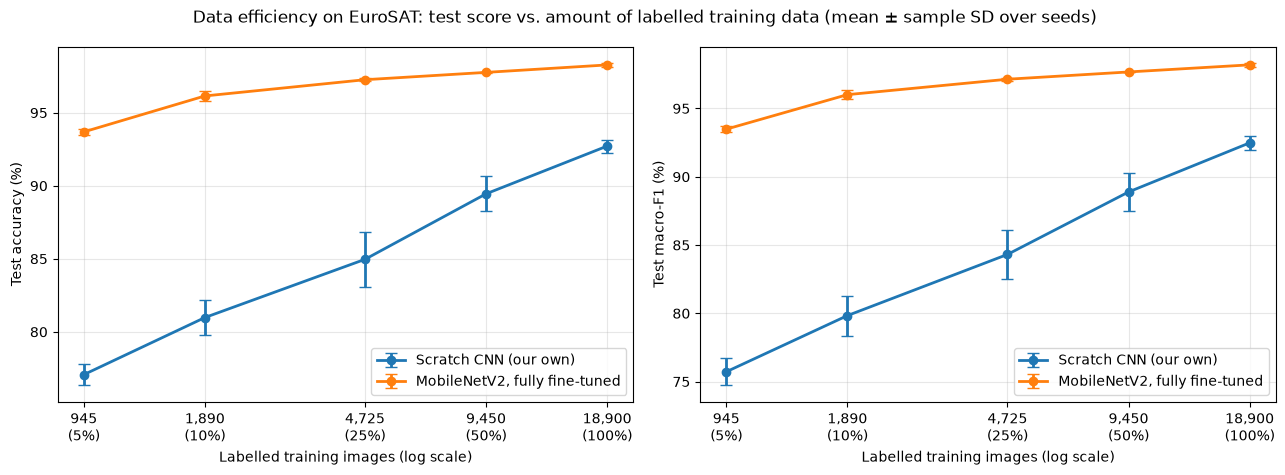

Saved C:\Users\Nitinshakthi\Desktop\3rd year DT\CNN and Deep Learning\eyes-in-the-sky\results\figures\data_efficiency.png


In [5]:
labels = {'scratch_cnn': 'Scratch CNN (our own)', 'mobilenet_v2_full': 'MobileNetV2, fully fine-tuned'}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
panels = [('accuracy_mean', 'accuracy_sd', 'Test accuracy (%)'), ('f1_mean', 'f1_sd', 'Test macro-F1 (%)')]
for ax, (mean_column, sd_column, title) in zip(axes, panels):
    for model in MODELS_TO_COMPARE:
        rows = summary[summary['model'] == model].sort_values('n_images')
        ax.errorbar(rows['n_images'], 100 * rows[mean_column], yerr=100 * rows[sd_column].fillna(0),
                    marker='o', capsize=4, linewidth=2, label=labels[model])
    ax.set_xscale('log')
    ax.set_xticks(SIZES)
    ax.set_xticklabels([f'{n:,}\n({f:.0%})' for n, f in zip(SIZES, FRACTIONS)])
    ax.minorticks_off()
    ax.set_xlabel('Labelled training images (log scale)')
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')
fig.suptitle('Data efficiency on EuroSAT: test score vs. amount of labelled training data (mean ± sample SD over seeds)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'data_efficiency.png', dpi=160)
plt.show()
print('Saved', FIGURES_DIR / 'data_efficiency.png')

## How big is the gap?

Difference in mean test accuracy, MobileNetV2 minus the scratch CNN, in percentage points, at each training size.

In [6]:
pivot = summary.pivot(index='n_images', columns='model', values='accuracy_mean') * 100
gap = pd.DataFrame({'scratch CNN (%)': pivot['scratch_cnn'], 'MobileNetV2 full (%)': pivot['mobilenet_v2_full']})
gap['gap (points)'] = gap['MobileNetV2 full (%)'] - gap['scratch CNN (%)']
display(gap.round(2))

,scratch CNN (%),MobileNetV2 full (%),gap (points)
n_images,,,
945,77.07,93.69,16.62
1890,80.98,96.15,15.17
4725,84.96,97.26,12.30
9450,89.45,97.76,8.31
18900,92.72,98.27,5.56


## What the results show

Numbers are test accuracy (mean over seeds 0, 1, 2) from the table and the plot above.

1. **Transfer learning helps most when labels are scarce.** With only 945 labelled images (5% of the training set) MobileNetV2 reaches 93.69%, which is about one point *better* than the scratch CNN trained on all 18,900 images (92.72%). That is about 20 times fewer labels for a slightly better score.
2. **The gap shrinks as data grows, but it does not close in this range.** It is 16.6 points at 5%, 15.2 at 10%, 12.3 at 25%, 8.3 at 50% and 5.6 points at 100%.
3. **The two curves have different shapes.** The scratch CNN is still climbing at 100% (it gains 3.3 points from 50% to 100%), so more labels would still help it. MobileNetV2 is flattening (0.5 points from 50% to 100%).
4. **The gap is much larger than the seed-to-seed spread.** The smallest gap is 5.6 points and the largest standard deviation is 1.9 points, so the conclusion does not depend on a lucky seed. With only 3 seeds the standard deviations themselves are rough estimates.

**Limits of this study (to repeat in the report):**

- Every size gets the same budget of up to 20 epochs. A smaller training set means fewer weight updates in total (945 images are only 15 batches per epoch), and the best epoch is often 17 to 20. So both models may be a little under-trained at the small sizes, and the small-data scores can understate what more epochs would give.
- MobileNetV2 was chosen on the *validation* set using the full training data (98.22% against 97.69% for ResNet-18 with full fine-tuning). It was not tuned again for each size, and its learning rate stayed at 0.0001.
- The 100% rows are the earlier Part B (`scratch_cnn`, from Tejash's own notebook helper, which `train()` later reproduced to within about 0.1 points on average) and Part C (`mobilenet_v2_full`, from Rachana's laptop) runs. The 5% to 50% rows come from this notebook on Nitin's RTX 3050.
- Seeds 3 and 4 (Srivalli and Rohan, on CPU laptops) are not included yet. If they are added, the small sizes will have 4 or 5 seeds and the large sizes 3.
- Both models are judged on a random split, which can put neighbouring patches of the same place in the training and the test images. Scores on truly new regions could be lower for both models.